[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_mathpendulum.ipynb)


## Математичний маятник

Задача про плоскі коливання математичного маятника є однією з основних у механіці. Вона розв’язується у квадратурах і зручна для перевірки різних аналітичних та чисельних методів. Рівняння руху має вигляд:

$$
\varphi ''\left(t\right) =-{\omega }^{2} \sin{\varphi} \\ {\omega }^{2} = g/l
$$

Характер руху залежить від повної енергії, яку можна визначити за швидкістю в найнижчій точці: $E=mv_0^2/2 <\left(>\right)\,mgl$. Значення $v_0=l\omega_0$ розділяє два режими руху: фінітний та «інфінітний».

Фінітний рух:

$$
\frac{{\left(\varphi '\right)}^{2}}{2}-{\omega }^{2}\cos{\varphi} =-{\omega }^{2}\cos{{\varphi }_{0}}\\ -{\int }_{{\varphi }_{0}}^{\varphi }\frac{1}{\sqrt{\cos{u}-\cos{{\varphi }_{0}}}}\mathrm{d}u=\sqrt{2} \omega  t
$$

Для простоти виберемо часовий масштаб так, щоб $\omega=1/\sqrt{2}$. Інтеграл у лівій частині не виражається через елементарні функції, оскільки належить до еліптичних інтегралів. Такі інтеграли виникали, зокрема, під час обчислення довжини дуги еліпса.

In [1]:
import numpy as np
import scipy.special as sc
from scipy.integrate import solve_ivp
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math
import ipywidgets as widgets

# The quadrature/period part of the source chooses omega = 1/sqrt(2).
phi, phi0 = sp.symbols('phi phi_0', real=True)
mpar = sp.sin(phi0/2)**2
primitive = sp.sqrt(2)*sp.elliptic_f(sp.asin(sp.sin(phi/2)/sp.sin(phi0/2)), mpar)
source_integral = primitive - sp.sqrt(2)*sp.elliptic_k(mpar)
display(Math(sp.latex(sp.Eq(sp.Integral(1/sp.sqrt(sp.cos(sp.Symbol('u'))-sp.cos(phi0)),
                                      (sp.Symbol('u'),phi0,phi)), source_integral))))


def tpend(phi, phi0):
    if not 0 < phi0 < np.pi:
        raise ValueError('The libration amplitude must lie between 0 and pi.')
    if np.any(np.abs(np.asarray(phi)) > phi0):
        raise ValueError('The angle must lie within the turning points.')
    k = np.sin(phi0/2)
    argument = np.arcsin(np.clip(np.sin(np.asarray(phi)/2)/k, -1, 1))
    return np.sqrt(2)*(sc.ellipk(k*k)-sc.ellipkinc(argument,k*k))


<IPython.core.display.Math object>

Функціональна залежність $t\left(\varphi\right)$:

$$
t\left(\varphi ; {\varphi }_{0}\right)=\frac{2 \left(EllipticF\left[\frac{\varphi }{2},{\csc{\frac{{\varphi }_{0}}{2}}}^{2}\right]-EllipticF\left[\frac{{\varphi }_{0}}{2},{\csc{\frac{{\varphi }_{0}}{2}}}^{2}\right]\right)}{\sqrt{1-\cos{{\varphi }_{0}}}}
$$

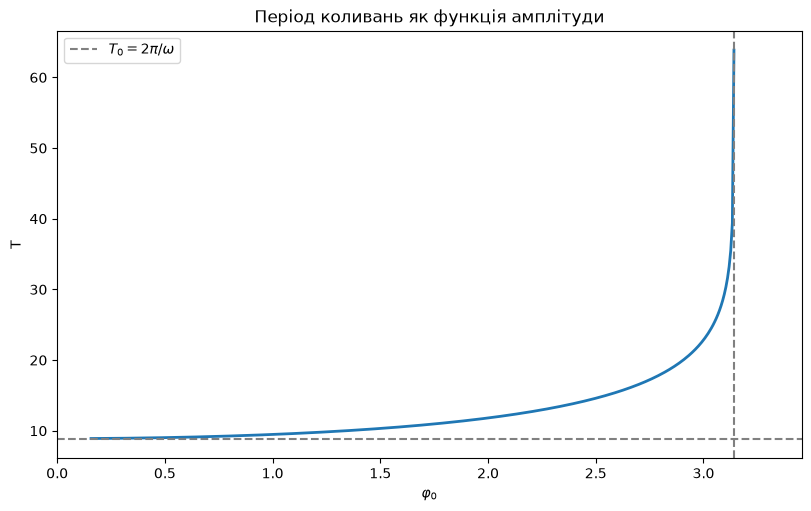

In [2]:
amplitudes = np.linspace(np.pi/20, np.pi-1e-4, 400)
periods = np.array([4*tpend(0, amplitude) for amplitude in amplitudes])
fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
ax.plot(amplitudes, periods, linewidth=2)
ax.axhline(2*np.pi*np.sqrt(2), color='gray', linestyle='--', label=r'$T_0=2\pi/\omega$')
ax.axvline(np.pi, color='gray', linestyle='--')
ax.set(xlim=(0,1.1*np.pi), xlabel=r'$\varphi_0$', ylabel='T',
       title='Період коливань як функція амплітуди')
ax.legend()
plt.show()


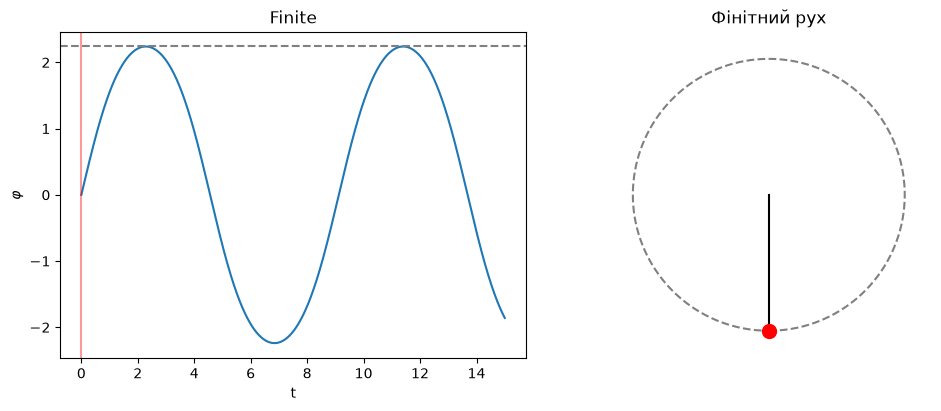

In [3]:
# The source's DSolve/Manipulate cell uses phi'' = -sin(phi), hence omega=1.
# Keep this distinct from the omega=1/sqrt(2) convention in the preceding cells.
def pendulum_angle(time, v0):
    time = np.asarray(time)
    if not 0 < v0 <= 3:
        raise ValueError('The initial speed must be positive and at most 3.')
    k = v0/2
    if v0 < 2:
        sn, cn, dn, amplitude = sc.ellipj(time, k*k)
        return 2*np.arcsin(np.clip(k*sn,-1,1))
    if v0 == 2:
        return 2*np.arctan(np.sinh(time))
    sn, cn, dn, amplitude = sc.ellipj(k*time, 1/(k*k))
    return 2*amplitude


def show_pendulum(v1=1.8, t1=0.0):
    times = np.linspace(0,15,1001)
    regime = 'Finite' if v1 < 2 else ('Separatrix' if v1 == 2 else 'Infinite')
    fig, axes = plt.subplots(1,2,figsize=(10,4),layout='constrained')
    axes[0].plot(times,pendulum_angle(times,v1))
    if v1 < 2:
        axes[0].axhline(2*np.arcsin(v1/2),color='gray',linestyle='--')
    axes[0].axvline(t1,color='red',alpha=0.4)
    axes[0].set(xlabel='t',ylabel=r'$\varphi$',title=regime)
    angle = float(pendulum_angle(t1,v1))
    theta = np.linspace(0,2*np.pi,300)
    axes[1].plot(np.sin(theta),-np.cos(theta),'--',color='gray')
    bob = (np.sin(angle),-np.cos(angle))
    axes[1].plot([0,bob[0]],[0,bob[1]],color='black')
    axes[1].plot(*bob,'ro',markersize=10)
    axes[1].set(xlim=(-1.2,1.2),ylim=(-1.2,1.2),aspect='equal',
                title='Фінітний рух' if v1 < 2 else 'Інфінітний рух')
    axes[1].axis('off')
    plt.show()


show_pendulum()
speed = widgets.FloatSlider(value=1.8,min=0.1,max=3,step=0.1,description='v₀',continuous_update=False)
clock = widgets.FloatSlider(value=0,min=0,max=10,step=0.05,description='t',continuous_update=False)
play = widgets.Play(value=0,min=0,max=200,step=1,interval=75,repeat=True)
# Play stores integer frame numbers; a callback maps them to the source time interval.
def advance(change):
    clock.value = change['new']/20
play.observe(advance,names='value')
view = widgets.interactive_output(show_pendulum,{'v1':speed,'t1':clock})
display(widgets.VBox([speed,widgets.HBox([play,clock]),view]))


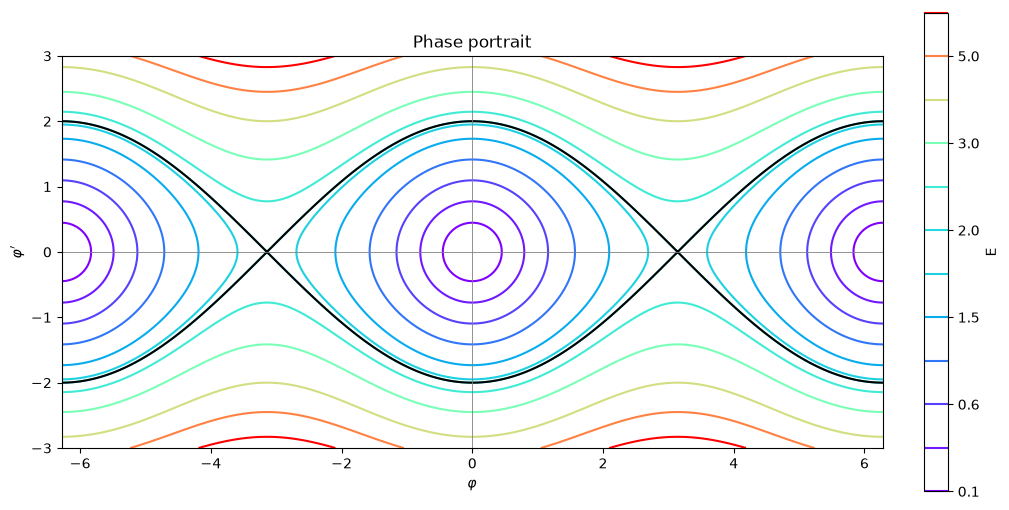

In [4]:
angles = np.linspace(-2*np.pi,2*np.pi,601)
speeds = np.linspace(-3,3,401)
angle_grid, speed_grid = np.meshgrid(angles,speeds)
energy = speed_grid**2/2+1-np.cos(angle_grid)
fig, ax = plt.subplots(figsize=(10,5),layout='constrained')
levels = [0.1,0.3,0.6,1,1.5,1.9,2,2.3,3,4,5,6]
contours = ax.contour(angle_grid,speed_grid,energy,levels=levels,cmap='rainbow')
ax.contour(angle_grid,speed_grid,energy,levels=[2],colors='black',linewidths=1.5)
ax.axhline(0,color='gray',linewidth=0.6)
ax.axvline(0,color='gray',linewidth=0.6)
ax.set(xlabel=r'$\varphi$',ylabel=r"$\varphi'$",title='Phase portrait',aspect='equal')
fig.colorbar(contours,ax=ax,label='E')
plt.show()


[Повернутися до змісту](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)